In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch


In [ ]:
#step-1 data cleaning
df=pd.read_csv("/content/COVID_Data.csv don't delete.zip")
df

,Unnamed: 0,Country,Date,Confirmed,Death,newConfirmed,newDeath
0,1,Afghanistan,2019-12-31,0,0,0,0
1,2,Afghanistan,2020-01-01,0,0,0,0
2,3,Afghanistan,2020-01-02,0,0,0,0
3,4,Afghanistan,2020-01-03,0,0,0,0
4,5,Afghanistan,2020-01-04,0,0,0,0
...,...,...,...,...,...,...,...
54517,55096,Zimbabwe,2020-11-02,8389,245,15,2
54518,55097,Zimbabwe,2020-11-03,8410,246,21,1
54519,55098,Zimbabwe,2020-11-04,8427,248,17,2
54520,55099,Zimbabwe,2020-11-05,8444,248,17,0


In [ ]:
#find the duplicates
df.duplicated()


,0
0,False
1,False
2,False
3,False
4,False
...,...
54517,False
54518,False
54519,False
54520,False


In [ ]:
#removing the duplicates
df.drop_duplicates(inplace=True)

In [ ]:
#rename the column names
df.rename(columns={ 'Confirmed':'Confirmedcase',  'newConfirmed':'newConfirmedCase','newDeath':'newDeathCase'},inplace=True)
df

,Unnamed: 0,Country,Date,Confirmedcase,Death,newConfirmedCase,newDeathCase
0,1,Afghanistan,2019-12-31,0,0,0,0
1,2,Afghanistan,2020-01-01,0,0,0,0
2,3,Afghanistan,2020-01-02,0,0,0,0
3,4,Afghanistan,2020-01-03,0,0,0,0
4,5,Afghanistan,2020-01-04,0,0,0,0
...,...,...,...,...,...,...,...
54517,55096,Zimbabwe,2020-11-02,8389,245,15,2
54518,55097,Zimbabwe,2020-11-03,8410,246,21,1
54519,55098,Zimbabwe,2020-11-04,8427,248,17,2
54520,55099,Zimbabwe,2020-11-05,8444,248,17,0


In [ ]:
#find the null values and counting the null values
df.isnull()
df.isnull().sum()



,0
Unnamed: 0,0
Country,0
Date,0
Confirmedcase,0
Death,0
newConfirmedCase,0
newDeathCase,0


In [ ]:
df.columns

Index(['Unnamed: 0', 'Country', 'Date', 'Confirmedcase', 'Death',
       'newConfirmedCase', 'newDeathCase'],
      dtype='object')

In [ ]:
df

,Unnamed: 0,Country,Date,Confirmedcase,Death,newConfirmedCase,newDeathCase
0,1,Afghanistan,2019-12-31,0,0,0,0
1,2,Afghanistan,2020-01-01,0,0,0,0
2,3,Afghanistan,2020-01-02,0,0,0,0
3,4,Afghanistan,2020-01-03,0,0,0,0
4,5,Afghanistan,2020-01-04,0,0,0,0
...,...,...,...,...,...,...,...
54517,55096,Zimbabwe,2020-11-02,8389,245,15,2
54518,55097,Zimbabwe,2020-11-03,8410,246,21,1
54519,55098,Zimbabwe,2020-11-04,8427,248,17,2
54520,55099,Zimbabwe,2020-11-05,8444,248,17,0


In [ ]:
# In my dataset new comfirmed case some negative value and then case the negative to postive values
df['newConfirmedCase']=abs(df['newConfirmedCase'])
df

,Unnamed: 0,Country,Date,Confirmedcase,Death,newConfirmedCase,newDeathCase
0,1,Afghanistan,2019-12-31,0,0,0,0
1,2,Afghanistan,2020-01-01,0,0,0,0
2,3,Afghanistan,2020-01-02,0,0,0,0
3,4,Afghanistan,2020-01-03,0,0,0,0
4,5,Afghanistan,2020-01-04,0,0,0,0
...,...,...,...,...,...,...,...
54517,55096,Zimbabwe,2020-11-02,8389,245,15,2
54518,55097,Zimbabwe,2020-11-03,8410,246,21,1
54519,55098,Zimbabwe,2020-11-04,8427,248,17,2
54520,55099,Zimbabwe,2020-11-05,8444,248,17,0


In [ ]:
df

,Unnamed: 0,Country,Date,Confirmedcase,Death,newConfirmedCase,newDeathCase
0,1,Afghanistan,2019-12-31,0,0,0,0
1,2,Afghanistan,2020-01-01,0,0,0,0
2,3,Afghanistan,2020-01-02,0,0,0,0
3,4,Afghanistan,2020-01-03,0,0,0,0
4,5,Afghanistan,2020-01-04,0,0,0,0
...,...,...,...,...,...,...,...
54517,55096,Zimbabwe,2020-11-02,8389,245,15,2
54518,55097,Zimbabwe,2020-11-03,8410,246,21,1
54519,55098,Zimbabwe,2020-11-04,8427,248,17,2
54520,55099,Zimbabwe,2020-11-05,8444,248,17,0


In [ ]:
#removing the uunwanted colnums
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

In [ ]:

df['Date'] = pd.to_datetime(
    df['Date'],
    format='%Y-%m-%d',
    errors='coerce'
)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54522 entries, 0 to 54521
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Country           54522 non-null  object        
 1   Date              54522 non-null  datetime64[ns]
 2   Confirmedcase     54522 non-null  int64         
 3   Death             54522 non-null  int64         
 4   newConfirmedCase  54522 non-null  int64         
 5   newDeathCase      54522 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 2.5+ MB


In [ ]:
df.columns

Index(['Country', 'Date', 'Confirmedcase', 'Death', 'newConfirmedCase',
       'newDeathCase'],
      dtype='object')

In [ ]:
df.to_csv('COVID_Datacleaning.csv')

In [ ]:
total_country=df['Country'].nunique()
total_confirmedcase=df['newConfirmedCase'].sum()
total_deaths=df['newDeathCase'].sum()

(np.float64(-0.5), np.float64(1671.5), np.float64(940.5), np.float64(-0.5))

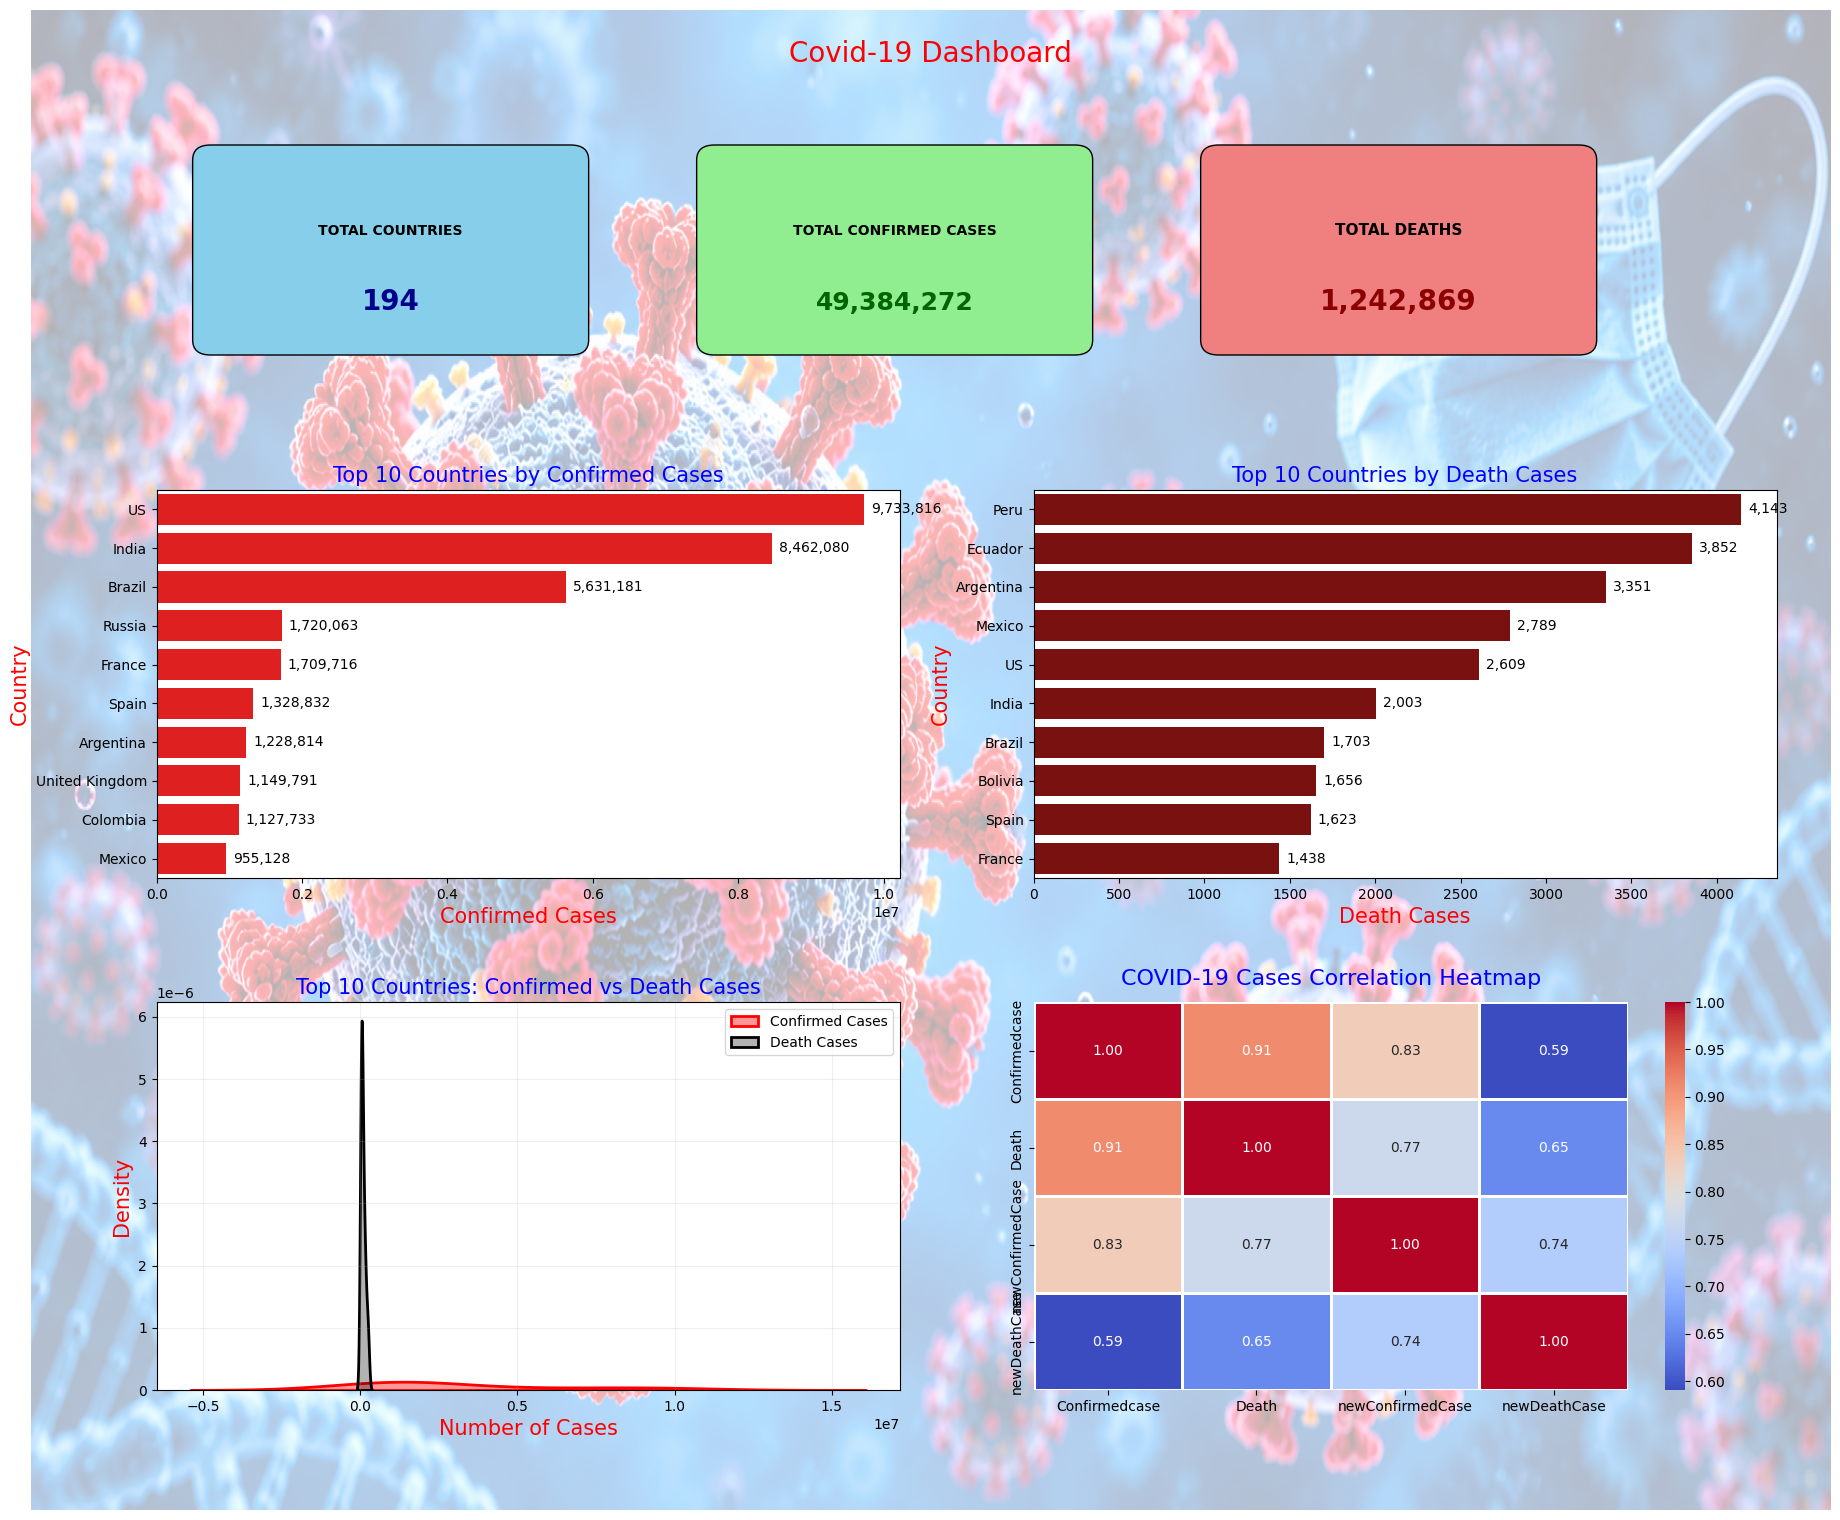

In [ ]:
fig,axes=plt.subplots(nrows=2,ncols=2,figsize=(18,15))
top_10 = df.groupby('Country')['Confirmedcase'].max().nlargest(10)
sns.barplot(
    x=top_10.values,
    y=top_10.index,
    ax=axes[0, 0],
    color='red'
)
for i, value in enumerate(top_10.values):
    axes[0, 0].annotate(
        f'{value:,.0f}',
        (value, i),
        ha='left',
        va='center',
        xytext=(5, 0),
        textcoords='offset points'
    )


axes[0, 0].set_title('Top 10 Countries by Confirmed Cases',color='blue',fontsize=15)
axes[0, 0].set_xlabel('Confirmed Cases',color='red',fontsize=15)
axes[0, 0].set_ylabel('Country',color='red',fontsize=15)
plt.tight_layout()
death_cases=df.groupby('Country')['newDeathCase'].max().nlargest(10)
sns.barplot(
    x=death_cases.values,
    y=death_cases.index,
    ax=axes[0, 1],
    color='darkred')
for i, value in enumerate(death_cases.values):
    axes[0, 1].annotate(
        f'{value:,.0f}',
        (value, i),
        ha='left',
        va='center',
        xytext=(5, 0),
        textcoords='offset points'
    )
axes[0, 1].set_title('Top 10 Countries by Death Cases',color='blue',fontsize=15)
axes[0, 1].set_xlabel('Death Cases',color='red',fontsize=15)
axes[0, 1].set_ylabel('Country',color='red',fontsize=15)
plt.tight_layout()
# Top 10 countries based on confirmed cases
top10 = (df.groupby('Country')[['Confirmedcase', 'Death']]
         .max()
         .nlargest(10, 'Confirmedcase'))

# KDE plot
sns.kdeplot(
    data=top10,
    x='Confirmedcase',
    fill=True,
    color='red',
    alpha=0.4,
    linewidth=2,
    label='Confirmed Cases',
    ax=axes[1,0]
)

sns.kdeplot(
    data=top10,
    x='Death',
    fill=True,
    color='black',
    alpha=0.3,
    linewidth=2,
    label='Death Cases',
    ax=axes[1,0]
)
plt.tight_layout()

# Customize plot
axes[1,0].set_title('Top 10 Countries: Confirmed vs Death Cases',
                    fontsize=15, color='blue')

axes[1,0].set_xlabel('Number of Cases',color='red',fontsize=15)
axes[1,0].set_ylabel('Density',color='red',fontsize=15)

axes[1,0].legend()
axes[1,0].grid(alpha=0.2)
sns.heatmap(
    df[['Confirmedcase', 'Death',
        'newConfirmedCase', 'newDeathCase']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1,
    ax=axes[1,1]
)

axes[1,1].set_title(
    'COVID-19 Cases Correlation Heatmap',
    fontsize=16,
  color='blue',
    pad=12
)
plt.tight_layout()

fig.subplots_adjust(
    top=0.68,
    bottom=0.08,
    left=0.07,
    right=0.97,
    hspace=0.32,
    wspace=0.18
)
plt.suptitle('Covid-19 Dashboard',color='red',fontsize=20)
card = FancyBboxPatch(
    (0.10, 0.78),
    0.20,
    0.12,
    boxstyle="round,pad=0.01",
    facecolor="skyblue",
    edgecolor="black",
    transform=fig.transFigure
)

fig.add_artist(card)

fig.text(0.20, 0.85, 'TOTAL COUNTRIES',
         ha='center', fontsize=10, fontweight='bold')

fig.text(0.20, 0.80, str(total_country),
         ha='center', fontsize=20, fontweight='bold',
         color='darkblue')
card2 = FancyBboxPatch(
    (0.38, 0.78),
    0.20,
    0.12,
    boxstyle="round,pad=0.01",
    facecolor="lightgreen",
    edgecolor="black",
    transform=fig.transFigure
)

fig.add_artist(card2)

# KPI heading
fig.text(
    0.48, 0.85,
    'TOTAL CONFIRMED CASES',
    ha='center',
    fontsize=10,
    fontweight='bold'
)

# KPI value
fig.text(
    0.48, 0.80,
    f'{total_confirmedcase:,}',
    ha='center',
    fontsize=18,
    fontweight='bold',
    color='darkgreen'
)
card3 = FancyBboxPatch(
    (0.66, 0.78),
    0.20,
    0.12,
    boxstyle="round,pad=0.01",
    facecolor="lightcoral",
    edgecolor="black",
    transform=fig.transFigure
)

fig.add_artist(card3)

# KPI heading
fig.text(
    0.76, 0.85,
    'TOTAL DEATHS',
    ha='center',
    fontsize=11,
    fontweight='bold'
)

# KPI value
fig.text(
    0.76, 0.80,
    f'{total_deaths:,}',
    ha='center',
    fontsize=20,
    fontweight='bold',
    color='darkred'
)
import matplotlib.image as mpimg
img=mpimg.imread('/content/Coronavirus and Surgical Mask in Blue Microscopic Scene.png')
bg = fig.add_axes([0, 0, 1, 1], zorder=-1)
bg.imshow(img, aspect='auto', alpha=0.3)
bg.axis('off')







In [ ]:
fig.savefig(
    'covid-19.jpg',
    dpi=384,
    bbox_inches='tight'
)